In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"
columns = [
    "checking_status", "duration", "credit_history", "purpose", "credit_amount",
    "savings_status", "employment", "installment_commitment", "personal_status",
    "other_parties", "residence_since", "property_magnitude", "age",
    "other_payment_plans", "housing", "existing_credits", "job",
    "num_dependents", "own_telephone", "foreign_worker", "class"
]

df = pd.read_csv(url, sep=" ", header=None, names=columns)
print(df.shape)
df.head()

(1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [28]:
df['bad_risk'] = df['class'].map({1: 0, 2: 1})

In [29]:
df.head()

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class,bad_risk,age_band
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A143,A152,2,A173,1,A192,A201,1,0,senior
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A143,A152,1,A173,1,A191,A201,2,1,young
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A143,A152,1,A172,2,A191,A201,1,0,middle_aged
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A143,A153,1,A173,2,A191,A201,1,0,middle_aged
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A143,A153,2,A173,2,A191,A201,2,1,middle_aged


In [30]:
df.shape

(1000, 23)

In [31]:
df.describe(include='object')

,checking_status,credit_history,purpose,savings_status,employment,personal_status,other_parties,property_magnitude,other_payment_plans,housing,job,own_telephone,foreign_worker
count,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000
unique,4,5,10,5,5,4,3,4,3,3,4,2,2
top,A14,A32,A43,A61,A73,A93,A101,A123,A143,A152,A173,A191,A201
freq,394,530,280,603,339,548,907,332,814,713,630,596,963


In [32]:
df['age_band'] = pd.cut(df['age'], bins=[18, 25, 40, 60, 100],
                          labels=['young', 'adult', 'middle_aged', 'senior'])
df.groupby('age_band')['bad_risk'].mean()

/tmp/ipykernel_972/207052651.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('age_band')['bad_risk'].mean()


,bad_risk
age_band,
young,0.421053
adult,0.276119
middle_aged,0.270742
senior,0.222222


In [33]:
df.groupby('age_band', observed=True)['bad_risk'].count()

,bad_risk
age_band,
young,190
adult,536
middle_aged,229
senior,45


In [37]:
df['monthly_repayment'] = df['credit_amount'] / df['duration']

In [41]:
import numpy as np
df['log_credit_amount'] = np.log(df['credit_amount'])

In [42]:
df[['credit_amount', 'duration', 'monthly_repayment', 'age', 'age_band', 'log_credit_amount']].head()

,credit_amount,duration,monthly_repayment,age,age_band,log_credit_amount
0,1169,6,194.833333,67,senior,7.063904
1,5951,48,123.979167,22,young,8.691315
2,2096,12,174.666667,49,middle_aged,7.647786
3,7882,42,187.666667,45,middle_aged,8.972337
4,4870,24,202.916667,53,middle_aged,8.490849


In [43]:
df['affordability_pressure'] = df['installment_commitment'] * df['monthly_repayment']

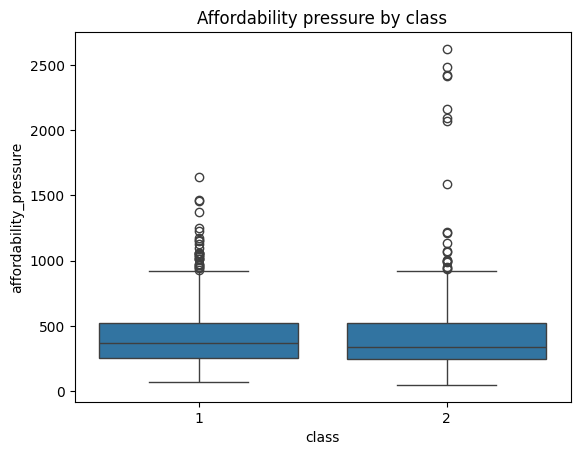

In [44]:
sns.boxplot(x='class', y='affordability_pressure', data=df)
plt.title('Affordability pressure by class')
plt.show()


In [36]:
df.columns.tolist()

['checking_status',
 'duration',
 'credit_history',
 'purpose',
 'credit_amount',
 'savings_status',
 'employment',
 'installment_commitment',
 'personal_status',
 'other_parties',
 'residence_since',
 'property_magnitude',
 'age',
 'other_payment_plans',
 'housing',
 'existing_credits',
 'job',
 'num_dependents',
 'own_telephone',
 'foreign_worker',
 'class',
 'bad_risk',
 'age_band']